# Xe cân bằng ESP32-S3: huấn luyện model điều khiển (Colab)

Notebook này huấn luyện một mạng nơ-ron nhỏ (MLP) để giữ thăng bằng xe 2 bánh, rồi xuất ra file C chạy trên ESP32-S3.

**Cách làm (teacher → student):**
1. Mô phỏng vật lý xe 2 bánh (con lắc ngược trên bánh xe) có động cơ DC, encoder, IMU nhiễu, độ trễ, vùng chết PWM.
2. **Teacher** = bộ LQR biết chính xác thông số của từng xe mô phỏng và trạng thái thật (không thể có ngoài đời).
3. **Student** = MLP chỉ thấy những gì ESP32 đo được: 8 mẫu cảm biến gần nhất + 3 lệnh PWM trước đó. Mỗi xe mô phỏng có thông số ngẫu nhiên (khối lượng, chiều cao trọng tâm, động cơ, pin...), nên student phải tự "đoán" xe đang thế nào từ lịch sử cảm biến.
4. Huấn luyện bằng DAgger (student lái, teacher chấm), so sánh với LQR thường trong cùng điều kiện, rồi lượng tử int8.

**Đầu ra:** `balance_policy.h` (float, chạy bằng C thuần, không cần thư viện), `balance_policy_int8.tflite` + `.h` (cho TensorFlow Lite Micro), `lqr_gains.h` (bộ LQR dự phòng).

Khi có mạch thật: sửa ô **Thông số xe** theo số đo thật rồi chạy lại toàn bộ (Runtime → Run all, ~5–10 phút trên CPU).

In [1]:
import numpy as np, scipy.linalg as sla, time, json, os
import matplotlib.pyplot as plt
import tensorflow as tf
np.set_printoptions(precision=4, suppress=True)
OUT = 'balancebot_out'; os.makedirs(OUT, exist_ok=True)
print('TensorFlow', tf.__version__)

I0000 00:00:1794403861.387544    1532 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794403861.428146    1532 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794403862.511019    1532 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Thông số xe (sửa theo xe thật)
Giá trị mặc định là xe cân bằng phổ biến: động cơ GA25-370 12 V 280 rpm (hộp số 1:34, encoder 11 xung), bánh 65 mm, pin 3S, thân cao ~18 cm.

In [2]:
NOMINAL = dict(
    M=0.85,      # kg, khối lượng thân (gồm pin, mạch)
    Lc=0.06,     # m, khoảng cách trục bánh -> trọng tâm thân
    Ib=0.0026,   # kg m^2, quán tính thân quanh trọng tâm (trục pitch)
    m=0.12,      # kg, tổng 2 bánh
    r=0.0325,    # m, bán kính bánh (bánh 65 mm)
    Irot=2.8e-4, # kg m^2, quán tính rotor quy về trục bánh (2 động cơ)
    Ts=0.50,     # N m, mô-men kẹt mỗi động cơ tại điện áp định mức
    w0=29.3,     # rad/s, tốc độ không tải tại điện áp định mức (280 rpm)
    Vn=12.0,     # V, điện áp định mức động cơ
    Vbat=11.1,   # V, pin 3S
    bm=0.002,    # N m s, ma sát nhớt động cơ
    br=0.001,    # N m s, ma sát lăn
    dz=0.07,     # vùng chết PWM (tỉ lệ duty)
    th_bias=0.0, # rad, sai lệch góc IMU sau hiệu chỉnh
)
CPR = 11 * 4 * 34          # xung encoder / vòng bánh (11 PPR x4 x 34)
DT = 0.005                 # chu kỳ điều khiển 200 Hz
SUB = 5                    # bước vật lý con mỗi chu kỳ (1 ms)
DZ_COMP = 0.07             # bù vùng chết trong firmware
FALL = 0.6                 # rad (~34°): coi như ngã, firmware tắt động cơ
H, NU = 8, 3               # số mẫu lịch sử cảm biến, số lệnh PWM trước đó
SCALE = np.array([0.3, 3.0, 20.0, 15.0], np.float32)  # chuẩn hoá [theta, theta_dot, phi_err, phi_dot_err]
N_IN = 4 * H + NU

## 2. Mô hình vật lý
Toạ độ: `theta` góc nghiêng thân (0 = thẳng đứng, + = nghiêng tới), `phi` góc quay tuyệt đối của bánh. Lệnh `u` ∈ [-1, 1] là duty PWM.

In [3]:
def motor_k(p):
    k1 = 2 * p['Ts'] * p['Vbat'] / p['Vn']   # N m trên 1 đơn vị duty
    k2 = 2 * p['Ts'] / p['w0']               # N m s/rad (sức phản điện động)
    return k1, k2

def deriv(th, thd, ph, phd, u_eff, p):
    """Đạo hàm trạng thái; các tham số có thể là mảng (N xe song song)."""
    k1, k2 = motor_k(p)
    w_rel = phd - thd
    tau = k1 * u_eff - (k2 + p['bm']) * w_rel
    M, Lc, r = p['M'], p['Lc'], p['r']
    m11 = p['Irot'] + 0.5 * p['m'] * r**2 + (p['m'] + M) * r**2
    m12 = M * r * Lc * np.cos(th)
    m22 = p['Ib'] + M * Lc**2
    s = np.sin(th)
    f1 = M * r * Lc * s * thd**2 + tau - p['br'] * phd
    f2 = M * 9.81 * Lc * s - tau
    det = m11 * m22 - m12**2
    phdd = (m22 * f1 - m12 * f2) / det
    thdd = (m11 * f2 - m12 * f1) / det
    return thdd, phdd

def linearize(p):
    """A, B liên tục quanh điểm thẳng đứng (sai phân hữu hạn)."""
    x0 = np.zeros(4); eps = 1e-6
    def f(x, u):
        thdd, phdd = deriv(x[0], x[1], x[2], x[3], u, p)
        return np.array([x[1], thdd, x[3], phdd])
    A = np.zeros((4, 4))
    for i in range(4):
        d = np.zeros(4); d[i] = eps
        A[:, i] = (f(x0 + d, 0) - f(x0 - d, 0)) / (2 * eps)
    B = ((f(x0, eps) - f(x0, -eps)) / (2 * eps)).reshape(4, 1)
    return A, B

Q_LQR = np.diag([1 / 0.03**2, 1 / 0.6**2, 1 / 12.0**2, 1 / 6.0**2, 0.0])
R_LQR = np.array([[1 / 0.35**2]])

def lqr_gain(p):
    """LQR rời rạc 200 Hz, có tính trễ 1 chu kỳ: trạng thái [theta, theta_dot, phi, phi_dot, u_truoc]."""
    A, B = linearize(p)
    n = 4
    Mx = np.zeros((n + 1, n + 1)); Mx[:n, :n] = A * DT; Mx[:n, n:] = B * DT
    E = sla.expm(Mx); Ad, Bd = E[:n, :n], E[:n, n:]
    Aa = np.zeros((5, 5)); Aa[:4, :4] = Ad; Aa[:4, 4:] = Bd
    Ba = np.zeros((5, 1)); Ba[4, 0] = 1.0
    P = sla.solve_discrete_are(Aa, Ba, Q_LQR, R_LQR)
    K = np.linalg.solve(R_LQR + Ba.T @ P @ Ba, Ba.T @ P @ Aa)
    eig = np.abs(np.linalg.eigvals(Aa - Ba @ K)).max()
    return K.ravel(), eig

K_NOM, eig = lqr_gain(NOMINAL)
A0, _ = linearize(NOMINAL)
print('Cực không ổn định của xe (rad/s):', np.round(np.linalg.eigvals(A0).real.max(), 2))
print('K LQR danh định:', K_NOM, ' |eig| lớn nhất vòng kín =', round(eig, 4))

Cực không ổn định của xe (rad/s): 7.5
K LQR danh định: [-7.0734 -0.4326 -0.0153 -0.1019  0.577 ]  |eig| lớn nhất vòng kín = 0.9979


## 3. Mô phỏng nhiều xe song song (thông số ngẫu nhiên, cảm biến thật)

In [4]:
RAND = dict(M=0.25, Lc=0.30, Ib=0.30, m=0.2, r=0.04, Irot=0.4, Ts=0.30, w0=0.2, bm=0.5, br=0.5)

def sample_params(n, rng, randomize=True):
    p = {}
    for k, v in NOMINAL.items():
        p[k] = np.full(n, float(v))
        if randomize and k in RAND:
            p[k] *= rng.uniform(1 - RAND[k], 1 + RAND[k], n)
    if randomize:
        p['Vbat'] = rng.uniform(10.5, 12.6, n)
        p['dz'] = rng.uniform(0.02, 0.12, n)
        p['th_bias'] = rng.uniform(-0.02, 0.02, n)
    return p

def per_robot_K(p):
    n = len(p['M']); Ks = np.zeros((n, 5))
    for i in range(n):
        Ks[i], _ = lqr_gain({k: v[i] for k, v in p.items()})
    return Ks

def duty_from_u(u):
    """Bù vùng chết như firmware: |u| nhỏ -> 0, còn lại đẩy lên trên vùng chết."""
    a = np.abs(u)
    return np.where(a < 1e-3, 0.0, np.sign(u) * np.clip(DZ_COMP + (1 - DZ_COMP) * a, 0, 1))

class Sim:
    def __init__(self, n, rng, randomize=True, th0=0.15, push=0.6, vel_cmd=4.0, T=10.0):
        self.n, self.rng, self.T = n, rng, T
        self.p = sample_params(n, rng, randomize)
        self.th = rng.uniform(-th0, th0, n); self.thd = np.zeros(n)
        self.ph = np.zeros(n); self.phd = np.zeros(n)
        self.u_prev = np.zeros(n)               # lệnh đang tác dụng (trễ 1 chu kỳ)
        self.alive = np.ones(n, bool)
        self.k = 0
        self.cnt_hist = np.zeros((5, n))        # đếm encoder 5 mẫu gần nhất
        self.phi_ref = np.zeros(n); self.phid_ref = np.zeros(n)
        self.gyro_bias = rng.normal(0, 0.005, n)
        self.push_t = {int(rng.uniform(2, 4) / DT), int(rng.uniform(5.5, 7.5) / DT)}
        self.push, self.vel_cmd = push, vel_cmd
        self.vel_switch = int(rng.uniform(3, 8) / DT)
        self.vel_target = rng.choice([-1.0, 0.0, 1.0], n) * rng.uniform(0, vel_cmd, n)

    def measure(self):
        """Giá trị ESP32 đo được (IMU sau lọc + encoder)."""
        rng, n = self.rng, self.n
        th_m = self.th + self.p['th_bias'] + rng.normal(0, 0.004, n)
        thd_m = self.thd + self.gyro_bias + rng.normal(0, 0.02, n)
        psi = self.ph - self.th                               # encoder đo góc bánh so với thân
        cnt = np.floor(psi * CPR / (2 * np.pi))
        self.cnt_hist = np.roll(self.cnt_hist, 1, axis=0); self.cnt_hist[0] = cnt
        ph_m = cnt * 2 * np.pi / CPR + th_m
        win = min(self.k, 4)
        psid = (self.cnt_hist[0] - self.cnt_hist[win]) * 2 * np.pi / CPR / (max(win, 1) * DT)
        phd_m = psid + thd_m
        return th_m, thd_m, ph_m, phd_m

    def obs(self, meas):
        th_m, thd_m, ph_m, phd_m = meas
        e_ph = np.clip(ph_m - self.phi_ref, -SCALE[2], SCALE[2])
        o = np.stack([th_m, thd_m, e_ph, phd_m - self.phid_ref], 1) / SCALE
        return np.clip(o, -3, 3).astype(np.float32)

    def teacher(self, K):
        """LQR biết trạng thái thật và thông số thật của từng xe."""
        e_ph = np.clip(self.ph - self.phi_ref, -SCALE[2], SCALE[2])
        x = np.stack([self.th, self.thd, e_ph, self.phd - self.phid_ref, self.u_prev], 1)
        return np.clip(-(K * x).sum(1), -1, 1)

    def step(self, u_cmd):
        """Áp lệnh của chu kỳ trước (trễ 1 chu kỳ), tích phân 5 bước 1 ms."""
        p = self.p
        d = duty_from_u(self.u_prev)
        u_eff = np.sign(d) * np.maximum(np.abs(d) - p['dz'], 0) / (1 - p['dz'])
        h = DT / SUB
        for _ in range(SUB):
            thdd, phdd = deriv(self.th, self.thd, self.ph, self.phd, u_eff, p)
            self.thd += thdd * h; self.phd += phdd * h
            self.th += self.thd * h; self.ph += self.phd * h
        self.u_prev = np.where(self.alive, np.clip(u_cmd, -1, 1), 0)
        self.k += 1
        if self.k in self.push_t:                       # đẩy tay vào thân xe
            self.thd += self.rng.uniform(-self.push, self.push, self.n)
        if self.k == self.vel_switch:                   # đổi lệnh tốc độ (chạy tới/lùi)
            self.phid_ref = self.vel_target.copy()
        self.phi_ref += self.phid_ref * DT
        fallen = np.abs(self.th) > FALL
        self.alive &= ~fallen
        # xe đã ngã: giữ nguyên để không làm hỏng số liệu
        self.th = np.where(self.alive, self.th, np.sign(self.th) * FALL)
        self.thd = np.where(self.alive, self.thd, 0)
        self.phd = np.where(self.alive, self.phd, 0)

def make_input(obs_hist, u_hist):
    """obs_hist: (H, n, 4) mới nhất trước; u_hist: (NU, n). -> (n, 35)"""
    return np.concatenate([obs_hist.transpose(1, 0, 2).reshape(obs_hist.shape[1], -1), u_hist.T], 1).astype(np.float32)

### Kiểm tra nhanh: LQR biết thông số thật (teacher) giữ được xe chưa?

In [5]:
rng = np.random.default_rng(0)
sim = Sim(64, rng)
Kt = per_robot_K(sim.p)
for k in range(int(sim.T / DT)):
    sim.measure(); sim.step(sim.teacher(Kt))
print(f'Teacher: {sim.alive.mean()*100:.0f}% xe không ngã sau {sim.T:.0f} s')

Teacher: 100% xe không ngã sau 10 s


## 4. Chạy thử nghiệm (rollout) với một bộ điều khiển bất kỳ

In [6]:
def rollout(n, seed, policy, collect=False, beta=0.0, randomize=True, every=2, log_one=False, T=10.0):
    """policy: None (teacher), 'lqr' (LQR danh định trên số đo), hoặc hàm f(X)->u."""
    rng = np.random.default_rng(seed)
    sim = Sim(n, rng, randomize=randomize, T=T)
    Kt = per_robot_K(sim.p)
    oh = np.zeros((H, n, 4), np.float32); uh = np.zeros((NU, n), np.float32)
    X, Y = [], []
    th_sq = np.zeros(n); ph_sq = np.zeros(n); cnt = 0
    log = []
    for k in range(int(T / DT)):
        meas = sim.measure()
        oh = np.roll(oh, 1, 0); oh[0] = sim.obs(meas)
        x_in = make_input(oh, uh)
        u_t = sim.teacher(Kt)
        if policy is None:
            u = u_t
        elif policy == 'lqr':
            th_m, thd_m, ph_m, phd_m = meas
            e_ph = np.clip(ph_m - sim.phi_ref, -SCALE[2], SCALE[2])
            xm = np.stack([th_m, thd_m, e_ph, phd_m - sim.phid_ref, sim.u_prev], 1)
            u = np.clip(-(xm @ K_NOM), -1, 1)
        else:
            u = policy(x_in)
            if beta > 0:
                mix = rng.random(n) < beta
                u = np.where(mix, u_t, u)
        if collect and k % every == 0:
            m = sim.alive
            X.append(x_in[m]); Y.append(u_t[m])
        if log_one:
            log.append([k * DT, sim.th[0], sim.ph[0] * NOMINAL['r'], sim.phi_ref[0] * NOMINAL['r'], u[0]])
        sim.step(u)
        uh = np.roll(uh, 1, 0); uh[0] = sim.u_prev
        if k * DT >= 1.0:
            th_sq += np.where(sim.alive, sim.th**2, 0); ph_sq += np.where(sim.alive, ((sim.ph - sim.phi_ref) * sim.p['r'])**2, 0); cnt += 1
    res = dict(alive=sim.alive.mean(),
               rms_th_deg=np.degrees(np.sqrt(th_sq[sim.alive].mean() / cnt)) if sim.alive.any() else np.nan,
               rms_pos_cm=100 * np.sqrt(ph_sq[sim.alive].mean() / cnt) if sim.alive.any() else np.nan)
    if collect:
        res['X'] = np.concatenate(X); res['Y'] = np.concatenate(Y).astype(np.float32)[:, None]
    if log_one:
        res['log'] = np.array(log)
    return res

t0 = time.time()
r_teacher = rollout(128, 1, None)
r_lqr = rollout(128, 1, 'lqr')
print(f"Teacher (biết thông số thật): {r_teacher['alive']*100:.0f}% đứng, RMS góc {r_teacher['rms_th_deg']:.2f}°")
print(f"LQR danh định (số đo thật):   {r_lqr['alive']*100:.0f}% đứng, RMS góc {r_lqr['rms_th_deg']:.2f}°  ({time.time()-t0:.1f} s)")

Teacher (biết thông số thật): 100% đứng, RMS góc 0.46°
LQR danh định (số đo thật):   100% đứng, RMS góc 0.77°  (1.2 s)


## 5. Mạng student và huấn luyện DAgger
MLP 35 → 48 → 48 → 1, kích hoạt tanh (đầu ra tanh = duty trong [-1, 1]). ~4 200 tham số, chạy trên ESP32-S3 dưới 50 µs.

In [7]:
def build_model():
    tf.keras.utils.set_random_seed(0)
    inp = tf.keras.Input((N_IN,), name='x')
    h = tf.keras.layers.Dense(48, activation='tanh', name='d1')(inp)
    h = tf.keras.layers.Dense(48, activation='tanh', name='d2')(h)
    out = tf.keras.layers.Dense(1, activation='tanh', name='u')(h)
    return tf.keras.Model(inp, out)

def np_policy(model):
    W = [l.get_weights() for l in model.layers[1:]]
    def f(x):
        h = np.tanh(x @ W[0][0] + W[0][1]); h = np.tanh(h @ W[1][0] + W[1][1])
        return np.tanh(h @ W[2][0] + W[2][1])[:, 0]
    return f

model = build_model()
model.compile(tf.keras.optimizers.Adam(2e-3), 'mse')
model.summary()

N_ROB, ITERS = 192, 6
D = rollout(N_ROB, 100, None, collect=True)          # vòng 0: teacher lái
X_all, Y_all = D['X'], D['Y']
hist = []
for it in range(ITERS):
    t0 = time.time()
    model.fit(X_all, Y_all, batch_size=1024, epochs=4 if it < ITERS - 1 else 10, verbose=0, shuffle=True)
    beta = max(0.0, 0.5 - 0.15 * it)                 # giảm dần phần teacher can thiệp
    D = rollout(N_ROB, 200 + it, np_policy(model), collect=True, beta=beta)
    X_all = np.concatenate([X_all, D['X']]); Y_all = np.concatenate([Y_all, D['Y']])
    ev = rollout(128, 999, np_policy(model))
    hist.append((it, ev['alive'], ev['rms_th_deg']))
    print(f'DAgger {it}: dữ liệu {len(X_all):>7d} mẫu | student tự lái: {ev["alive"]*100:5.1f}% đứng, RMS góc {ev["rms_th_deg"]:.2f}° ({time.time()-t0:.0f} s)')
model.fit(X_all, Y_all, batch_size=1024, epochs=10, verbose=0, shuffle=True)
model.save(f'{OUT}/balance_policy.keras')

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ x (InputLayer)                  │ (None, 35)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ d1 (Dense)                      │ (None, 48)             │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ d2 (Dense)                      │ (None, 48)             │         2,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ u (Dense)                       │ (None, 1)              │            49 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,129 (16.13 KB)

 Trainable params: 4,129 (16.13 KB)

 Non-trainable params: 0 (0.00 B)

DAgger 0: dữ liệu  384000 mẫu | student tự lái:   0.0% đứng, RMS góc nan° (5 s)


DAgger 1: dữ liệu  576000 mẫu | student tự lái:  67.2% đứng, RMS góc 0.93° (6 s)


DAgger 2: dữ liệu  768000 mẫu | student tự lái:  14.1% đứng, RMS góc 2.19° (6 s)


DAgger 3: dữ liệu  959897 mẫu | student tự lái:  99.2% đứng, RMS góc 0.92° (10 s)


DAgger 4: dữ liệu 1150978 mẫu | student tự lái:  98.4% đứng, RMS góc 0.98° (9 s)


DAgger 5: dữ liệu 1342978 mẫu | student tự lái: 100.0% đứng, RMS góc 0.86° (23 s)


## 6. Lượng tử int8 (TFLite) và đánh giá vòng kín
So sánh trên 300 xe mô phỏng mới (thông số ngẫu nhiên, đẩy tay 2 lần, đổi lệnh tốc độ), cùng một seed cho mọi bộ điều khiển.

In [8]:
rep = X_all[np.random.default_rng(0).choice(len(X_all), 2000, replace=False)]
conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = lambda: ([r[None]] for r in rep)
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8; conv.inference_output_type = tf.int8
tfl = conv.convert()
open(f'{OUT}/balance_policy_int8.tflite', 'wb').write(tfl)
print('Kích thước model int8:', len(tfl), 'byte')

def tflite_policy(buf, n):
    it = tf.lite.Interpreter(model_content=buf)
    it.resize_tensor_input(it.get_input_details()[0]['index'], [n, N_IN]); it.allocate_tensors()
    di, do = it.get_input_details()[0], it.get_output_details()[0]
    si, zi = di['quantization']; so, zo = do['quantization']
    def f(x):
        q = np.clip(np.round(x / si + zi), -128, 127).astype(np.int8)
        it.set_tensor(di['index'], q); it.invoke()
        return (it.get_tensor(do['index']).astype(np.float32) - zo) * so
    return f, (si, zi, so, zo)

NE = 300
f_int8, qparams = tflite_policy(tfl, NE)
rows = []
for name, pol in [('Teacher (biết thông số thật – không có ngoài đời)', None), ('LQR danh định', 'lqr'),
                  ('MLP float (C thuần trên ESP32)', np_policy(model)), ('MLP int8 (TFLite Micro)', lambda x: f_int8(x)[:, 0])]:
    r = rollout(NE, 2024, pol)
    rows.append((name, r['alive'] * 100, r['rms_th_deg'], r['rms_pos_cm']))
print(f"{'Bộ điều khiển':52s} {'% đứng':>7s} {'RMS góc':>8s} {'RMS vị trí':>11s}")
for n_, a, t_, p_ in rows:
    print(f'{n_:52s} {a:6.1f}% {t_:7.2f}° {p_:9.1f} cm')
json.dump([dict(name=n_, alive_pct=a, rms_theta_deg=t_, rms_pos_cm=p_) for n_, a, t_, p_ in rows], open(f'{OUT}/eval.json', 'w'), indent=1, ensure_ascii=False)

INFO:tensorflow:Assets written to: /tmp/tmpx58jrj8l/assets


INFO:tensorflow:Assets written to: /tmp/tmpx58jrj8l/assets


Saved artifact at '/tmp/tmpx58jrj8l'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 35), dtype=tf.float32, name='x')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140649699671504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140649696675216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140649696674832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140649696675600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140649696675408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140649696675024: TensorSpec(shape=(), dtype=tf.resource, name=None)


Kích thước model int8: 9344 byte


/usr/local/lib/python3.13/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1794403948.913148    1532 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794403948.913175    1532 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794403948.913551    1532 reader.cc:83] Reading SavedModel from: /tmp/tmpx58jrj8l
I0000 00:00:1794403948.913879    1532 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794403948.913883    1532 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpx58jrj8l
I0000 00:00:1794403948.916360    1532 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1794403948.916911    1532 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1794403948.938394    1532 loader.cc:220] Running initialization op on SavedModel bundle at p

Bộ điều khiển                                         % đứng  RMS góc  RMS vị trí
Teacher (biết thông số thật – không có ngoài đời)     100.0%    0.48°       6.0 cm
LQR danh định                                         100.0%    0.72°      22.2 cm
MLP float (C thuần trên ESP32)                        100.0%    0.51°       9.4 cm
MLP int8 (TFLite Micro)                               100.0%    0.55°       8.3 cm


### Xe danh định: góc nghiêng và vị trí theo thời gian (MLP float)

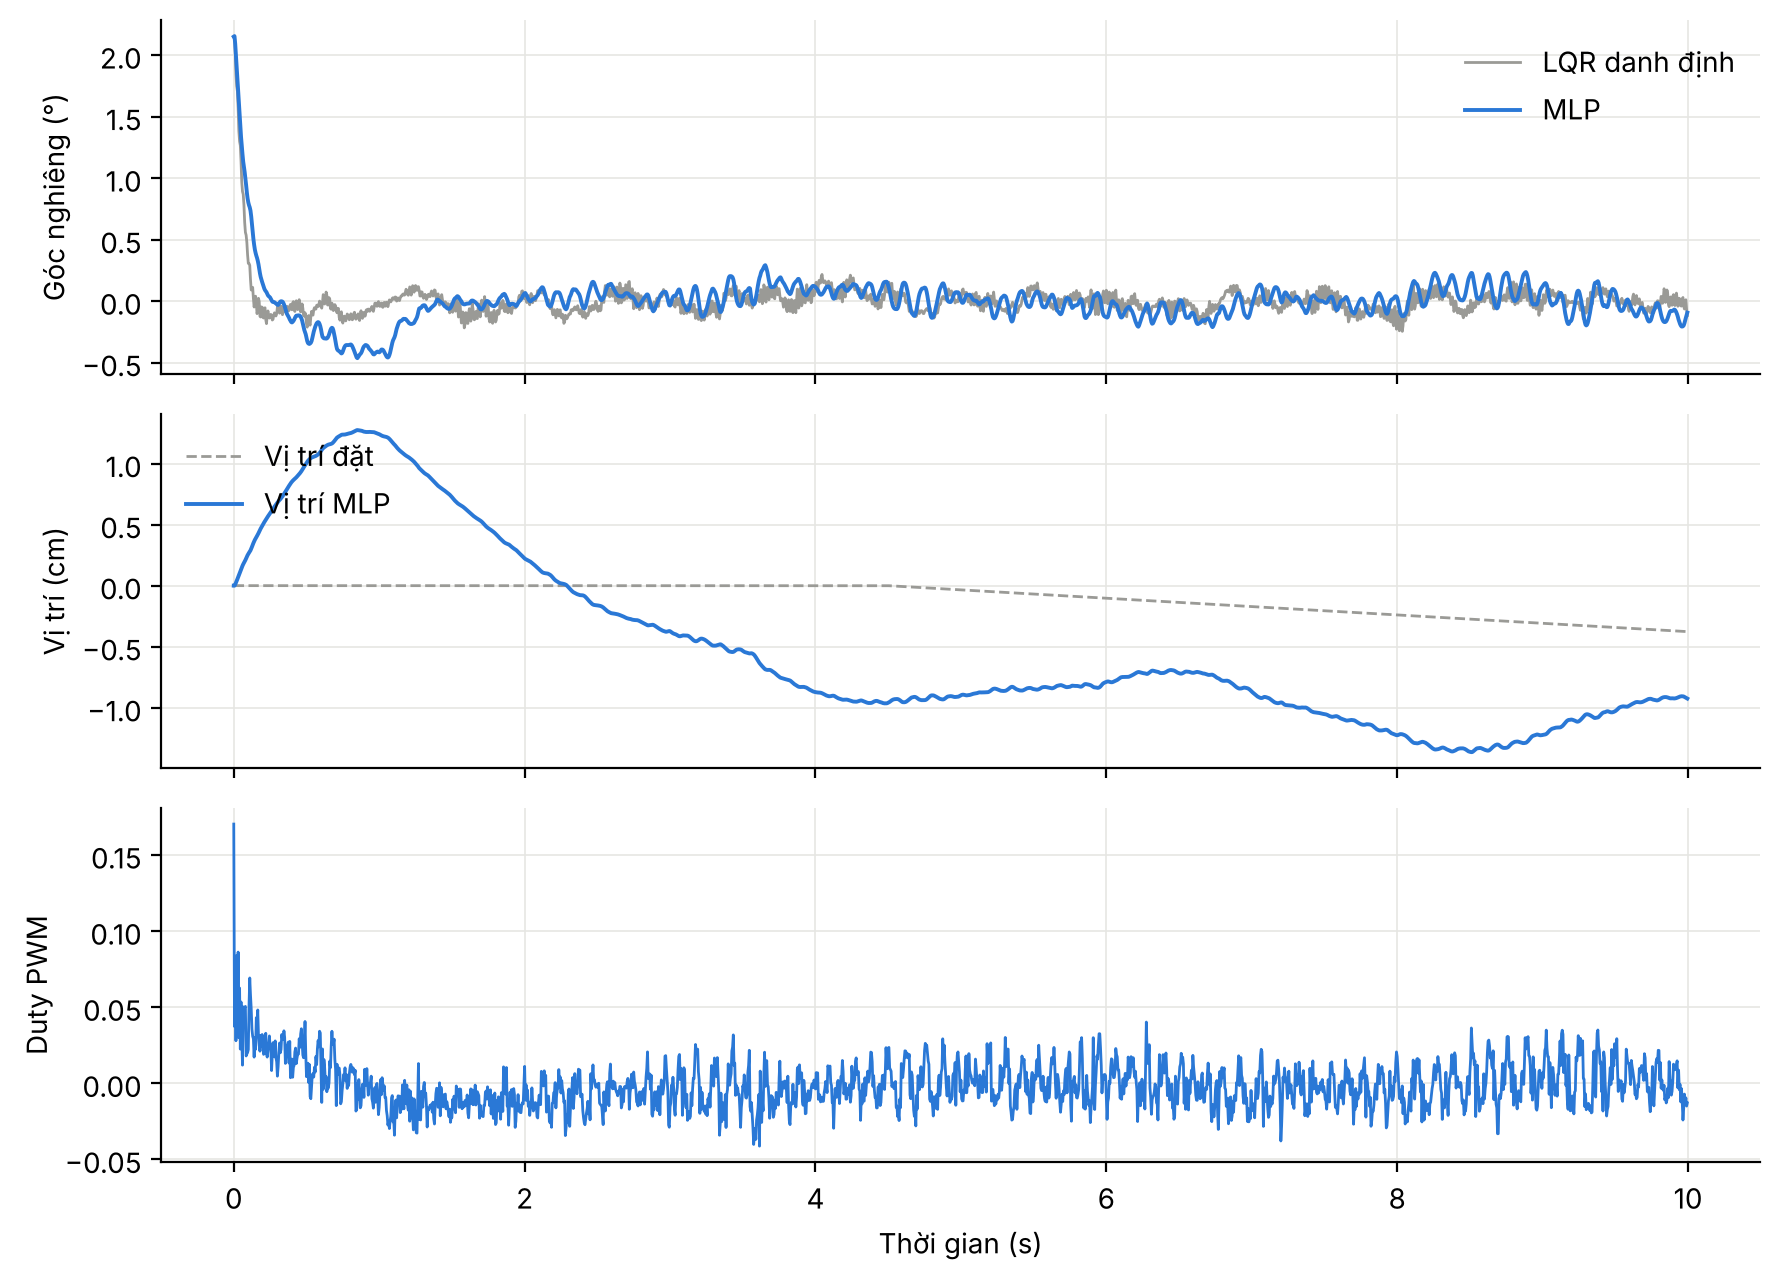

In [9]:
lg = rollout(1, 7, np_policy(model), randomize=False, log_one=True)['log']
lq = rollout(1, 7, 'lqr', randomize=False, log_one=True)['log']
fig, ax = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True)
ax[0].plot(lq[:, 0], np.degrees(lq[:, 1]), color='#9a9a96', lw=1, label='LQR danh định')
ax[0].plot(lg[:, 0], np.degrees(lg[:, 1]), color='#2a78d6', lw=1.4, label='MLP')
ax[0].set_ylabel('Góc nghiêng (°)'); ax[0].legend(frameon=False, loc='upper right')
ax[1].plot(lg[:, 0], 100 * lg[:, 3], color='#9a9a96', lw=1, ls='--', label='Vị trí đặt')
ax[1].plot(lg[:, 0], 100 * lg[:, 2], color='#2a78d6', lw=1.4, label='Vị trí MLP')
ax[1].set_ylabel('Vị trí (cm)'); ax[1].legend(frameon=False, loc='upper left')
ax[2].plot(lg[:, 0], lg[:, 4], color='#2a78d6', lw=1)
ax[2].set_ylabel('Duty PWM'); ax[2].set_xlabel('Thời gian (s)')
for a in ax:
    a.spines[['top', 'right']].set_visible(False); a.grid(color='#e6e6e3', lw=0.6)
plt.tight_layout(); plt.savefig(f'{OUT}/closed_loop.png', dpi=150); plt.show()

## 7. Xuất file cho ESP32-S3

In [10]:
def c_arr(name, a, ctype='float', fmt='{:.8e}f'):
    a = np.asarray(a).ravel()
    body = ',\n  '.join(', '.join(fmt.format(v) for v in a[i:i + 8]) for i in range(0, len(a), 8))
    return f'static const {ctype} {name}[{len(a)}] = {{\n  {body}\n}};\n'

W = [l.get_weights() for l in model.layers[1:]]
hdr = ['// Sinh tự động từ notebook BalanceBot_ESP32S3_Colab.ipynb - không sửa tay',
       '#pragma once', f'#define BP_H {H}', f'#define BP_NU {NU}', f'#define BP_IN {N_IN}',
       f'#define BP_H1 {W[0][0].shape[1]}', f'#define BP_H2 {W[1][0].shape[1]}',
       f'#define BP_DT_S {DT}f', f'#define BP_CPR {CPR}', f'#define BP_DZ_COMP {DZ_COMP}f', f'#define BP_FALL_RAD {FALL}f',
       '// Thứ tự đầu vào: [obs(t), obs(t-1), ..., obs(t-7), u(t-1), u(t-2), u(t-3)]',
       '// obs = [theta, theta_dot, clamp(phi-phi_ref, +-SCALE[2]), phi_dot-phi_dot_ref] / SCALE, clamp +-3',
       c_arr('BP_SCALE', SCALE),
       '// Trọng số lưu theo hàng: W[i*out + j] = nối đầu vào i -> nơ-ron j',
       c_arr('BP_W1', W[0][0]), c_arr('BP_B1', W[0][1]),
       c_arr('BP_W2', W[1][0]), c_arr('BP_B2', W[1][1]),
       c_arr('BP_W3', W[2][0]), c_arr('BP_B3', W[2][1])]
open(f'{OUT}/balance_policy.h', 'w').write('\n'.join(hdr))

# vector kiểm thử: C phải ra đúng như Python
tv = X_all[np.random.default_rng(1).choice(len(X_all), 16, replace=False)]
ty = model.predict(tv, verbose=0)[:, 0]
open(f'{OUT}/balance_policy_test.h', 'w').write('#pragma once\n#define BP_NTEST 16\n' + c_arr('BP_TEST_X', tv) + c_arr('BP_TEST_Y', ty))

open(f'{OUT}/lqr_gains.h', 'w').write(
    '// LQR danh định (dự phòng): u = -(K0*theta + K1*theta_dot + K2*phi_err + K3*phi_dot_err + K4*u_prev)\n#pragma once\n'
    + c_arr('LQR_K', K_NOM))

si, zi, so, zo = qparams
xxd = ', '.join(f'0x{b:02x}' for b in tfl)
open(f'{OUT}/balance_policy_int8.h', 'w').write(
    '// Model TFLite int8 cho TensorFlow Lite Micro (tuỳ chọn)\n#pragma once\n#include <stdint.h>\n'
    f'#define BP_Q_IN_SCALE {si:.8e}f\n#define BP_Q_IN_ZERO {zi}\n#define BP_Q_OUT_SCALE {so:.8e}f\n#define BP_Q_OUT_ZERO {zo}\n'
    f'alignas(16) static const uint8_t balance_policy_int8[{len(tfl)}] = {{ {xxd} }};\n')
print('Đã xuất:', sorted(os.listdir(OUT)))

Đã xuất: ['balance_policy.h', 'balance_policy.keras', 'balance_policy_int8.h', 'balance_policy_int8.tflite', 'balance_policy_test.h', 'closed_loop.png', 'eval.json', 'lqr_gains.h']


## 8. (Khi có xe thật) Tinh chỉnh bằng dữ liệu đo trên xe
Firmware có lệnh `log` in ra Serial từng dòng `L,<35 đầu vào>,<u của LQR>` trong lúc xe tự cân bằng bằng LQR. Lưu thành `real_log.csv`, tải lên Colab rồi chạy ô dưới để tinh chỉnh (học bắt chước LQR trên dữ liệu thật, trộn với dữ liệu mô phỏng), sau đó chạy lại mục 6–7.

In [11]:
if os.path.exists('real_log.csv'):
    R = np.loadtxt('real_log.csv', delimiter=',', usecols=range(1, N_IN + 2), dtype=np.float32)
    Xr, Yr = R[:, :N_IN], R[:, N_IN:]
    mix = np.random.default_rng(0).choice(len(X_all), min(len(X_all), 4 * len(Xr)), replace=False)
    model.compile(tf.keras.optimizers.Adam(5e-4), 'mse')
    model.fit(np.concatenate([Xr, X_all[mix]]), np.concatenate([Yr, Y_all[mix]]), batch_size=512, epochs=8, verbose=1)
    print('Đã tinh chỉnh với', len(Xr), 'mẫu thật -> chạy lại mục 6 và 7')
else:
    print('Chưa có real_log.csv - bỏ qua bước này')

Chưa có real_log.csv - bỏ qua bước này


## 9. Tải kết quả về máy
Chép `balance_policy.h`, `lqr_gains.h` (và `balance_policy_int8.h` nếu dùng TFLite Micro) vào thư mục `include/` của project PlatformIO rồi build lại.

In [12]:
import shutil
shutil.make_archive('balancebot_model', 'zip', OUT)
try:
    from google.colab import files
    files.download('balancebot_model.zip')
except ImportError:
    print('Không chạy trên Colab: file nằm ở balancebot_model.zip')

Không chạy trên Colab: file nằm ở balancebot_model.zip
